In [1]:

import os
import gc
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

import timm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("PyTorch:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.11.0+cu130
GPU Available: True
GPU: Tesla T4


In [2]:

import os

for root, dirs, files in os.walk("/kaggle/input"):
    if root.count(os.sep) <= 4:
        print(root, "Folders:", dirs[:10])


/kaggle/input Folders: ['datasets']
/kaggle/input/datasets Folders: ['masoudnickparvar']
/kaggle/input/datasets/masoudnickparvar Folders: ['brain-tumor-mri-dataset']


In [3]:

# Automatically find dataset folders

DATA_ROOT = "/kaggle/input"

train_dir = None
test_dir = None

for root, dirs, files in os.walk(DATA_ROOT):
    folder_names = {d.lower(): d for d in dirs}

    if "training" in folder_names and "testing" in folder_names:
        train_dir = os.path.join(root, folder_names["training"])
        test_dir = os.path.join(root, folder_names["testing"])
        break

if train_dir is None:
    raise FileNotFoundError(
        "Training and Testing folders not found. "
        "Check the dataset path from Step 3."
    )

print("Training path:", train_dir)
print("Testing path:", test_dir)

# Read class names
temp_dataset = datasets.ImageFolder(train_dir)

classes = temp_dataset.classes
class_names = classes
targets = temp_dataset.targets

print("\nClasses:", classes)
print("Number of training images:", len(temp_dataset))

test_temp = datasets.ImageFolder(test_dir)

print("Number of testing images:", len(test_temp))
print("Test classes:", test_temp.classes)

assert temp_dataset.class_to_idx == test_temp.class_to_idx, \
    "Training and testing class folders do not match!"


Training path: /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training
Testing path: /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Number of training images: 5600
Number of testing images: 1600
Test classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


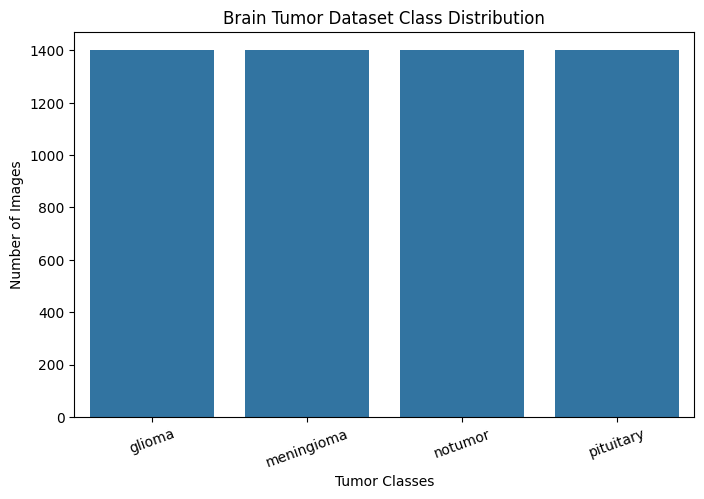

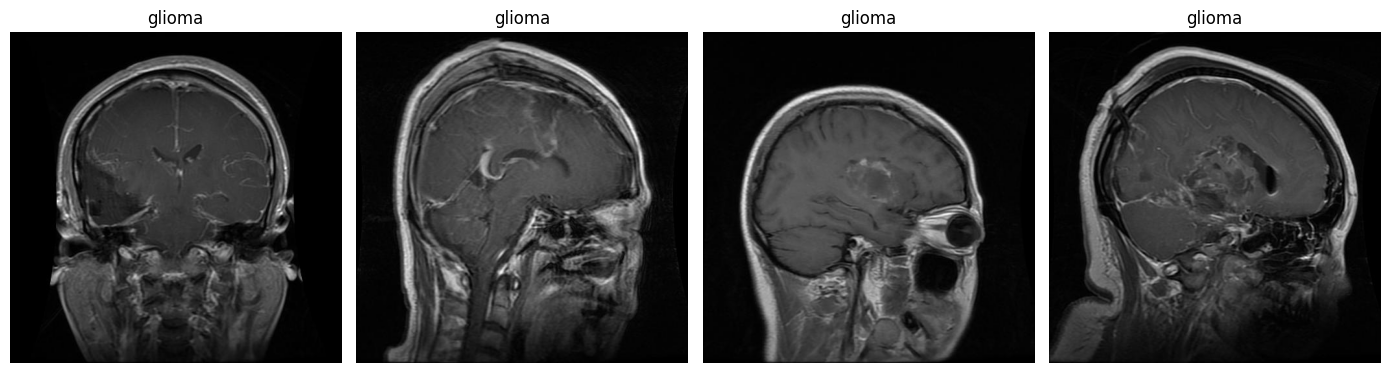

In [4]:

# Class distribution

class_counts = pd.Series(targets).value_counts().sort_index()

plt.figure(figsize=(8, 5))
sns.barplot(
    x=classes,
    y=[class_counts[i] for i in range(len(classes))]
)
plt.title("Brain Tumor Dataset Class Distribution")
plt.xlabel("Tumor Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)
plt.show()

# Display sample images

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for i, ax in enumerate(axes):
    image, label = temp_dataset[i]
    ax.imshow(image)
    ax.set_title(classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [6]:

indices = np.arange(len(temp_dataset))

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.15,
    random_state=42,
    stratify=targets
)

print("Training samples:", len(train_indices))
print("Validation samples:", len(val_indices))
print("Testing samples:", len(test_temp))


Training samples: 4760
Validation samples: 840
Testing samples: 1600


In [7]:

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

EPOCHS = 10
BATCH_SIZE = 16
LEARNING_RATE = 0.0001
PATIENCE = 3
NUM_WORKERS = 2

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

def get_loaders(image_size):

    train_transform = transforms.Compose([
        transforms.Resize((image_size, image_size)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(10),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD)
    ])

    eval_transform = transforms.Compose([
        transforms.Resize((image_size, image_size)),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD)
    ])

    train_dataset = datasets.ImageFolder(
        train_dir, transform=train_transform
    )

    val_dataset = datasets.ImageFolder(
        train_dir, transform=eval_transform
    )

    test_dataset = datasets.ImageFolder(
        test_dir, transform=eval_transform
    )

    train_subset = Subset(train_dataset, train_indices)
    val_subset = Subset(val_dataset, val_indices)

    train_loader = DataLoader(
        train_subset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )

    val_loader = DataLoader(
        val_subset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )

    return train_loader, val_loader, test_loader

print("Device:", DEVICE)


Device: cuda


In [8]:

# Find available pretrained model names in timm

available_models = timm.list_models(pretrained=True)

def find_model(candidates, pattern):
    for name in candidates:
        if name in available_models:
            return name

    matches = [
        name for name in available_models
        if pattern in name
    ]

    if matches:
        return matches[0]

    raise ValueError(
        f"No pretrained model found for {pattern}. "
        "Check timm model availability."
    )

MAXVIT_NAME = find_model(
    ["maxvit_tiny_tf_224.in1k"],
    "maxvit_tiny"
)

SWINV2_NAME = find_model(
    ["swinv2_tiny_window8_256.ms_in1k"],
    "swinv2_tiny"
)

print("Model 1:", MAXVIT_NAME)
print("Model 2:", SWINV2_NAME)


Model 1: maxvit_tiny_tf_224.in1k
Model 2: swinv2_tiny_window8_256.ms_in1k


In [10]:

def train_model(model, train_loader, val_loader, model_name):

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=0.01
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=2
    )

    scaler = torch.cuda.amp.GradScaler(
        enabled=(DEVICE.type == "cuda")
    )

    best_val_loss = float("inf")
    patience_counter = 0

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    save_path = f"/kaggle/working/{model_name}_best.pth"

    for epoch in range(EPOCHS):

        start_time = time.time()

        # Training
        model.train()

        train_loss = 0
        train_correct = 0
        train_total = 0

        for images, labels in train_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            with torch.cuda.amp.autocast(
                enabled=(DEVICE.type == "cuda")
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            train_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            train_correct += (predictions == labels).sum().item()
            train_total += labels.size(0)

        train_loss /= train_total
        train_acc = train_correct / train_total

        # Validation
        model.eval()

        val_loss = 0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(DEVICE)
                labels = labels.to(DEVICE)

                with torch.cuda.amp.autocast(
                    enabled=(DEVICE.type == "cuda")
                ):
                    outputs = model(images)
                    loss = criterion(outputs, labels)

                val_loss += loss.item() * labels.size(0)

                predictions = outputs.argmax(dim=1)

                val_correct += (predictions == labels).sum().item()
                val_total += labels.size(0)

        val_loss /= val_total
        val_acc = val_correct / val_total

        scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:

            best_val_loss = val_loss
            patience_counter = 0

            torch.save(model.state_dict(), save_path)

        else:
            patience_counter += 1

        elapsed = time.time() - start_time

        print(
            f"Epoch {epoch+1}/{EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc*100:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc*100:.2f}% | "
            f"Time: {elapsed:.1f}s"
        )

        if patience_counter >= PATIENCE:
            print("Early stopping activated.")
            break

    model.load_state_dict(
        torch.load(save_path, map_location=DEVICE)
    )

    return model, history, save_path


In [11]:

def train_model(model, train_loader, val_loader, model_name):

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=0.01
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=2
    )

    scaler = torch.cuda.amp.GradScaler(
        enabled=(DEVICE.type == "cuda")
    )

    best_val_loss = float("inf")
    patience_counter = 0

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    save_path = f"/kaggle/working/{model_name}_best.pth"

    for epoch in range(EPOCHS):

        start_time = time.time()

        # Training
        model.train()

        train_loss = 0
        train_correct = 0
        train_total = 0

        for images, labels in train_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            with torch.cuda.amp.autocast(
                enabled=(DEVICE.type == "cuda")
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            train_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            train_correct += (predictions == labels).sum().item()
            train_total += labels.size(0)

        train_loss /= train_total
        train_acc = train_correct / train_total

        # Validation
        model.eval()

        val_loss = 0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(DEVICE)
                labels = labels.to(DEVICE)

                with torch.cuda.amp.autocast(
                    enabled=(DEVICE.type == "cuda")
                ):
                    outputs = model(images)
                    loss = criterion(outputs, labels)

                val_loss += loss.item() * labels.size(0)

                predictions = outputs.argmax(dim=1)

                val_correct += (predictions == labels).sum().item()
                val_total += labels.size(0)

        val_loss /= val_total
        val_acc = val_correct / val_total

        scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:

            best_val_loss = val_loss
            patience_counter = 0

            torch.save(model.state_dict(), save_path)

        else:
            patience_counter += 1

        elapsed = time.time() - start_time

        print(
            f"Epoch {epoch+1}/{EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc*100:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc*100:.2f}% | "
            f"Time: {elapsed:.1f}s"
        )

        if patience_counter >= PATIENCE:
            print("Early stopping activated.")
            break

    model.load_state_dict(
        torch.load(save_path, map_location=DEVICE)
    )

    return model, history, save_path


In [13]:

# Load MaxViT-Tiny

model1 = timm.create_model(
    MAXVIT_NAME,
    pretrained=True,
    num_classes=len(classes)
).to(DEVICE)

size1 = model1.pretrained_cfg["input_size"][-1]

print("MaxViT input size:", size1)

train_loader, val_loader, test_loader = get_loaders(size1)

model1, history1, path1 = train_model(
    model1,
    train_loader,
    val_loader,
    "MaxViT_Tiny"
)

result1 = evaluate_model(
    model1,
    test_loader,
    "MaxViT-Tiny"
)


MaxViT input size: 224


/tmp/ipykernel_50/4287471406.py:18: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(
/tmp/ipykernel_50/4287471406.py:52: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/tmp/ipykernel_50/4287471406.py:86: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(


Epoch 1/10 | Train Loss: 0.3107 | Train Acc: 88.87% | Val Loss: 0.1048 | Val Acc: 96.79% | Time: 71.3s
Epoch 2/10 | Train Loss: 0.0800 | Train Acc: 97.27% | Val Loss: 0.0792 | Val Acc: 97.38% | Time: 68.6s
Epoch 3/10 | Train Loss: 0.0418 | Train Acc: 98.61% | Val Loss: 0.0432 | Val Acc: 98.21% | Time: 68.2s
Epoch 4/10 | Train Loss: 0.0314 | Train Acc: 98.91% | Val Loss: 0.1475 | Val Acc: 94.40% | Time: 67.7s
Epoch 5/10 | Train Loss: 0.0357 | Train Acc: 98.78% | Val Loss: 0.0587 | Val Acc: 98.33% | Time: 67.7s
Epoch 6/10 | Train Loss: 0.0306 | Train Acc: 98.82% | Val Loss: 0.0198 | Val Acc: 99.52% | Time: 68.0s
Epoch 7/10 | Train Loss: 0.0158 | Train Acc: 99.39% | Val Loss: 0.0377 | Val Acc: 99.05% | Time: 67.7s
Epoch 8/10 | Train Loss: 0.0109 | Train Acc: 99.64% | Val Loss: 0.0148 | Val Acc: 99.52% | Time: 68.2s
Epoch 9/10 | Train Loss: 0.0192 | Train Acc: 99.41% | Val Loss: 0.0592 | Val Acc: 97.98% | Time: 67.9s
Epoch 10/10 | Train Loss: 0.0223 | Train Acc: 99.29% | Val Loss: 0.0305 |

NameError: name 'evaluate_model' is not defined

In [15]:

def evaluate_model(model, test_loader, model_name):

    model.eval()

    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in test_loader:

            images = images.to(DEVICE)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            all_labels.extend(labels.numpy())
            all_predictions.extend(predictions.cpu().numpy())

    accuracy = accuracy_score(all_labels, all_predictions)
    precision = precision_score(
        all_labels, all_predictions,
        average="macro", zero_division=0
    )
    recall = recall_score(
        all_labels, all_predictions,
        average="macro", zero_division=0
    )
    f1 = f1_score(
        all_labels, all_predictions,
        average="macro", zero_division=0
    )

    print("\n", model_name, "TEST RESULTS")
    print("Accuracy:", accuracy * 100)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1-score:", f1)

    print("\nClassification Report:")
    print(classification_report(
        all_labels, all_predictions,
        target_names=classes,
        zero_division=0
    ))

    cm = confusion_matrix(all_labels, all_predictions)

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=classes,
        yticklabels=classes
    )
    plt.title(model_name + " Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    return {
        "Model": model_name,
        "Accuracy": accuracy * 100,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    }



 MaxViT-Tiny TEST RESULTS
Accuracy: 95.125
Precision: 0.9547765445711629
Recall: 0.95125
F1-score: 0.950191925106445

Classification Report:
              precision    recall  f1-score   support

      glioma       0.99      0.82      0.90       400
  meningioma       0.89      0.98      0.93       400
     notumor       0.94      1.00      0.97       400
   pituitary       1.00      1.00      1.00       400

    accuracy                           0.95      1600
   macro avg       0.95      0.95      0.95      1600
weighted avg       0.95      0.95      0.95      1600



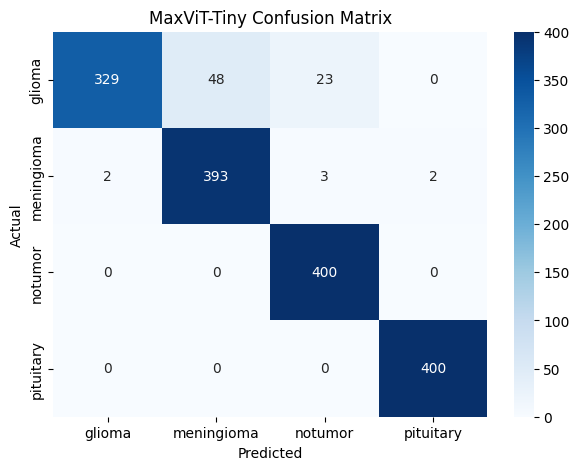

In [16]:
result1 = evaluate_model(
    model1,
    test_loader,
    "MaxViT-Tiny"
)

In [17]:

import gc
import torch

del model1

gc.collect()
torch.cuda.empty_cache()

print("GPU memory cleared")
print("Second model is ready")


GPU memory cleared
Second model is ready


In [18]:

model2 = timm.create_model(
    SWINV2_NAME,
    pretrained=True,
    num_classes=len(classes)
).to(DEVICE)

size2 = model2.pretrained_cfg["input_size"][-1]

print("Model:", SWINV2_NAME)
print("Image size:", size2)
print("Number of classes:", len(classes))


model.safetensors: reconstructing file:   0%|          |  0.00B /  115MB            

model.safetensors: downloading bytes:           |  0.00B            

Model: swinv2_tiny_window8_256.ms_in1k
Image size: 256
Number of classes: 4


In [19]:

BATCH_SIZE = 8

train_loader, val_loader, test_loader = get_loaders(size2)

print("Training images:", len(train_indices))
print("Validation images:", len(val_indices))
print("Testing images:", len(test_temp))


Training images: 4760
Validation images: 840
Testing images: 1600


In [20]:

model2, history2, path2 = train_model(
    model2,
    train_loader,
    val_loader,
    "SwinV2_Tiny"
)


/tmp/ipykernel_50/4287471406.py:18: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(
/tmp/ipykernel_50/4287471406.py:52: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/tmp/ipykernel_50/4287471406.py:86: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(


Epoch 1/10 | Train Loss: 0.3231 | Train Acc: 88.57% | Val Loss: 0.1689 | Val Acc: 93.69% | Time: 70.0s
Epoch 2/10 | Train Loss: 0.1196 | Train Acc: 96.30% | Val Loss: 0.0692 | Val Acc: 97.62% | Time: 69.3s
Epoch 3/10 | Train Loss: 0.0900 | Train Acc: 97.02% | Val Loss: 0.0966 | Val Acc: 97.14% | Time: 69.2s
Epoch 4/10 | Train Loss: 0.0787 | Train Acc: 97.42% | Val Loss: 0.0273 | Val Acc: 99.05% | Time: 69.0s
Epoch 5/10 | Train Loss: 0.0559 | Train Acc: 98.30% | Val Loss: 0.0722 | Val Acc: 97.62% | Time: 69.0s
Epoch 6/10 | Train Loss: 0.0632 | Train Acc: 98.03% | Val Loss: 0.0186 | Val Acc: 99.52% | Time: 68.9s
Epoch 7/10 | Train Loss: 0.0474 | Train Acc: 98.47% | Val Loss: 0.0555 | Val Acc: 98.57% | Time: 69.0s
Epoch 8/10 | Train Loss: 0.0497 | Train Acc: 98.49% | Val Loss: 0.0878 | Val Acc: 97.02% | Time: 68.7s
Epoch 9/10 | Train Loss: 0.0473 | Train Acc: 98.49% | Val Loss: 0.1676 | Val Acc: 95.24% | Time: 69.0s
Early stopping activated.



 Swin Transformer V2 Tiny TEST RESULTS
Accuracy: 94.875
Precision: 0.9523020190231622
Recall: 0.9487500000000001
F1-score: 0.9474283463453483

Classification Report:
              precision    recall  f1-score   support

      glioma       0.99      0.81      0.89       400
  meningioma       0.89      0.99      0.94       400
     notumor       0.95      1.00      0.97       400
   pituitary       0.98      1.00      0.99       400

    accuracy                           0.95      1600
   macro avg       0.95      0.95      0.95      1600
weighted avg       0.95      0.95      0.95      1600



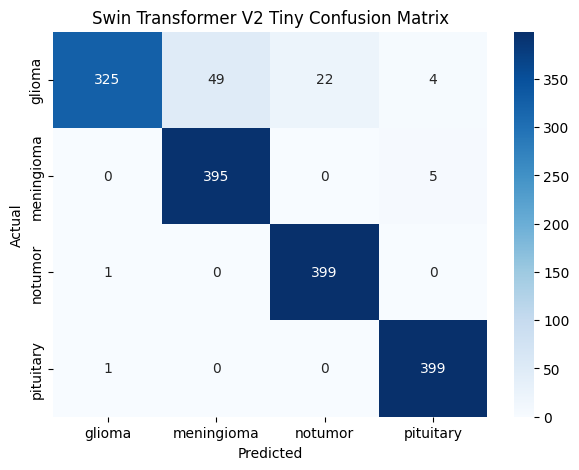

In [21]:

result2 = evaluate_model(
    model2,
    test_loader,
    "Swin Transformer V2 Tiny"
)


FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-score
0,MaxViT-Tiny,95.125,0.9548,0.9512,0.9502
1,Swin Transformer V2 Tiny,94.875,0.9523,0.9488,0.9474


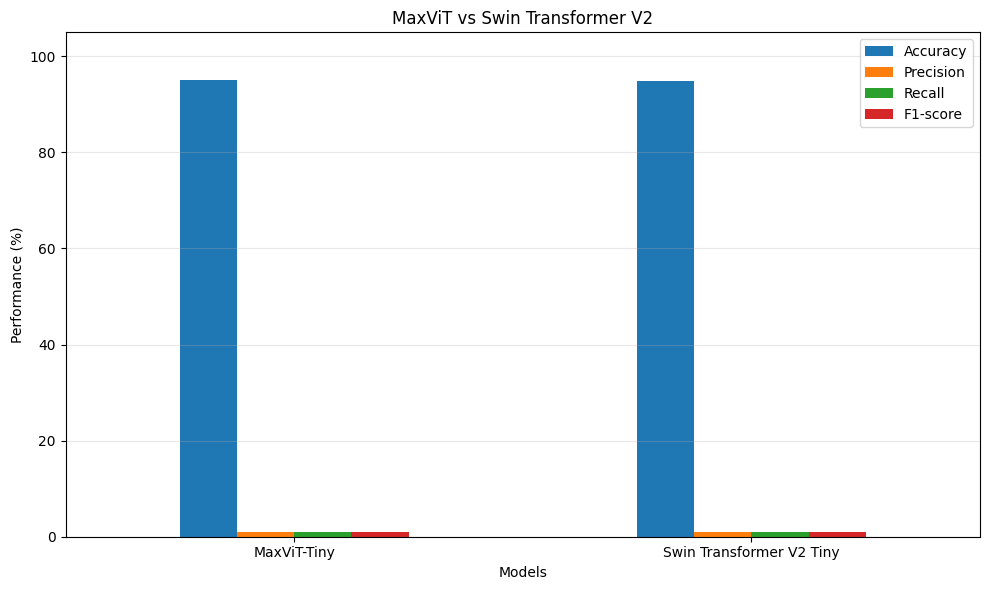

In [22]:

results = pd.DataFrame([result1, result2])

print("FINAL MODEL COMPARISON")
display(results.round(4))

results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
].plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 105),
    rot=0
)

plt.title("MaxViT vs Swin Transformer V2")
plt.ylabel("Performance (%)")
plt.xlabel("Models")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
